# README

# Handwritten Digit Classifier from Scratch

A NumPy neural network that classifies 28×28 grayscale images
into digits from 0 to 9.

## What I implemented
- Forward propagation and backpropagation
- ReLU and softmax
- Mini-batch gradient descent
- Learning-rate reduction and early stopping
- Accuracy, cross-entropy loss, and macro F1

## Architecture
784 inputs → 10 hidden neurons → 10 output classes

##### - lowkey struggled a bit tryna match the dimensions for matrix multiplication

## Data preparation
Pixel values are divided by 255.
The data is split into training and validation sets.

## Results
Best validation loss: approximately 0.23.

## Heres What I learned:
In Machine Learning, when training an AI using the splitted data, in every epoch, the same data is used. Though this risks overfitting but it doesn't automatically cause it.

What I built was an MLP, a multi layer perceptron. This is specifically a shallow network because it only contains one hidden layer. Having multiple hidden layers turns it into a Deep Neural Network.

This network is a feed forward network. Pretty obvious ik ik  :>

Batching is taking the entire train test split and feeding it into the network while mini batches is taking small bite size peices of train test split and feeding it to the network.

Loss is basically the penalty. The lower it is, the better.

Precision basically says "out of all the images the network called (class_y), how many were really (class_y)? Used for minimizing the false alarms.

Recall as the word suggests, in a way its how well the model remembers. Out of all that really were (class_y), how many did the model find? Used for minimizing missed cases.

F1 score is the combination of precision and recall, its how well the model balances finding the right answers and voiding wrong guesses.

Macro F1 score is the average of the f1 scores of each class. (Note that each class have equal weights, meaning each class counts equally regardless of how many images it has).

Train Accuracy is not to be trusted and used as a basis for improvement. Best to use Validation Loss and Validation accuracy.

----------------------------------------------------------------------------
Xavier initialization chooses a starting weight scale that helps prevent signals and gradients from growing or shrinking repeatedly across layers, under suitable assumptions. Random sampling lets neurons start differently.
- Xavier uniform samples weights between −a and +a. These boundaries are symmetric around zero, but the sampled weights are not guaranteed to contain equal numbers of positive and negative values.

- ReLU changes negative weighted sums to zero. For roughly symmetric, zero-centered weighted sums, this removes about half of their average squared signal. Repeating that reduction across many layers can make signals very small.

Kaiming initialization chooses a larger weight variance to compensate for this reduction. For equal-width layers, standard Kaiming weights have √2 times the standard deviation of standard Xavier weights. This doubles the weight variance, helping maintain signal size through ReLU layers under the initialization assumptions.

- Kaiming normal samples from a zero-centered bell curve. Large magnitudes are possible but rare. Kaiming uniform uses fixed boundaries instead.

Neither method guarantees that gradients will remain well behaved throughout training.


• With Xavier + ReLU: By the time you get to a 50-layer deep network, your signal variance is practically zero (0.5⁵⁰). The network can't learn because the activations vanish.
• The Kaiming Fix: Kaiming multiplies the weights by \(\sqrt{2}\). This effectively doubles the variance at each layer, exactly compensating for the 50% loss caused by ReLU. It keeps the network alive on step zero.

----------------------------------------------------------------------------
    
How gradients update weights, how to evaluate a classifier,
and how to debug an inactive ReLU layer.

## Other concepts I applied

**Input normalization:** I divided pixel values by 255 to change their range from 0–255 to 0–1. This preserves the image shades while controlling the input scale.

**Matrix operations and vectorization:** I represented images as columns and processed multiple images with matrix multiplication, instead of calculating each neuron and image separately.

**Biases:** Each neuron has a learned offset added to its weighted sum. This lets the neuron shift its activation point.

**Activation functions:** ReLU introduces a nonlinear operation between weight layers. Without it, my two weight layers would be equivalent to one linear transformation.

**Softmax and argmax:** Softmax converts output scores into probabilities that sum to 1 for each image. Argmax selects the class with the largest probability.

**Cross-entropy loss:** I penalized the model based on the probability it assigned to the correct class. A higher correct-class probability produces a lower loss.

**Backpropagation and the chain rule:** I calculated how the loss changes with each weight and bias by working backward through the network. The chain rule connects these changes across layers.

**Mini-batch gradient descent:** I averaged gradient contributions across each training batch, then updated the weights and biases once per batch.

**Learning rate:** This controls how strongly each gradient changes a parameter. It multiplies the gradient; it is not the full update size by itself.

**Validation:** I measured performance on separate images without updating weights. This helped guide training decisions.

**Whole-epoch metrics:** I accumulated correct counts, image counts, and loss sums across batches. I then calculated metrics for the whole dataset pass.

**Confusion matrix:** I counted actual–predicted class pairs to identify which digits the model confused. I also used those counts to calculate per-class F1.

**Learning-rate reduction on a plateau:** When validation loss stopped improving for several epochs, I reduced the learning rate to allow smaller updates.

**Early stopping and patience:** I allowed several epochs without improvement before taking action. After the permitted learning-rate reductions, further stalling stopped training.

**Best-model checkpointing:** I saved copies of weights and biases whenever validation loss reached a new best value. At the end, I restored that checkpoint.

**Numerical stability:** I subtracted the largest score before calculating softmax exponentials to prevent overflow. I clipped probabilities before taking logarithms to avoid log(0).

**Debugging with measurements:** I inspected gradient sizes, the learning rate, and the fraction of positive hidden activations to investigate stalled learning.

**Reproducible initialization:** I used a random seed so I could reproduce the same initial weights.




This neural network was one heck of a y = mx + b, with a few bends and a lot of adjustable knobs.

# Starting up 
#### [Loading the dataset and reading]

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score, log_loss

df = pd.read_csv("/kaggle/input/competitions/digit-recognizer/train.csv")
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,pixel11,pixel12,pixel13,pixel14,pixel15,pixel16,pixel17,pixel18,pixel19,pixel20,pixel21,pixel22,pixel23,pixel24,pixel25,pixel26,pixel27,pixel28,pixel29,pixel30,pixel31,pixel32,pixel33,pixel34,pixel35,pixel36,pixel37,pixel38,pixel39,pixel40,pixel41,pixel42,pixel43,pixel44,pixel45,pixel46,pixel47,pixel48,pixel49,pixel50,pixel51,pixel52,pixel53,pixel54,pixel55,pixel56,pixel57,pixel58,pixel59,pixel60,pixel61,pixel62,pixel63,pixel64,pixel65,pixel66,pixel67,pixel68,pixel69,pixel70,pixel71,pixel72,pixel73,pixel74,pixel75,pixel76,pixel77,pixel78,pixel79,pixel80,pixel81,pixel82,pixel83,pixel84,pixel85,pixel86,pixel87,pixel88,pixel89,pixel90,pixel91,pixel92,pixel93,pixel94,pixel95,pixel96,pixel97,pixel98,pixel99,pixel100,pixel101,pixel102,pixel103,pixel104,pixel105,pixel106,pixel107,pixel108,pixel109,pixel110,pixel111,pixel112,pixel113,pixel114,pixel115,pixel116,pixel117,pixel118,pixel119,pixel120,pixel121,pixel122,pixel123,pixel124,pixel125,pixel126,pixel127,pixel128,pixel129,pixel130,pixel131,pixel132,pixel133,pixel134,pixel135,pixel136,pixel137,pixel138,pixel139,pixel140,pixel141,pixel142,pixel143,pixel144,pixel145,pixel146,pixel147,pixel148,pixel149,pixel150,pixel151,pixel152,pixel153,pixel154,pixel155,pixel156,pixel157,pixel158,pixel159,pixel160,pixel161,pixel162,pixel163,pixel164,pixel165,pixel166,pixel167,pixel168,pixel169,pixel170,pixel171,pixel172,pixel173,pixel174,pixel175,pixel176,pixel177,pixel178,pixel179,pixel180,pixel181,pixel182,pixel183,pixel184,pixel185,pixel186,pixel187,pixel188,pixel189,pixel190,pixel191,pixel192,pixel193,pixel194,pixel195,pixel196,pixel197,pixel198,pixel199,pixel200,pixel201,pixel202,pixel203,pixel204,pixel205,pixel206,pixel207,pixel208,pixel209,pixel210,pixel211,pixel212,pixel213,pixel214,pixel215,pixel216,pixel217,pixel218,pixel219,pixel220,pixel221,pixel222,pixel223,pixel224,pixel225,pixel226,pixel227,pixel228,pixel229,pixel230,pixel231,pixel232,pixel233,pixel234,pixel235,pixel236,pixel237,pixel238,pixel239,pixel240,pixel241,pixel242,pixel243,pixel244,pixel245,pixel246,pixel247,pixel248,pixel249,pixel250,pixel251,pixel252,pixel253,pixel254,pixel255,pixel256,pixel257,pixel258,pixel259,pixel260,pixel261,pixel262,pixel263,pixel264,pixel265,pixel266,pixel267,pixel268,pixel269,pixel270,pixel271,pixel272,pixel273,pixel274,pixel275,pixel276,pixel277,pixel278,pixel279,pixel280,pixel281,pixel282,pixel283,pixel284,pixel285,pixel286,pixel287,pixel288,pixel289,pixel290,pixel291,pixel292,pixel293,pixel294,pixel295,pixel296,pixel297,pixel298,pixel299,pixel300,pixel301,pixel302,pixel303,pixel304,pixel305,pixel306,pixel307,pixel308,pixel309,pixel310,pixel311,pixel312,pixel313,pixel314,pixel315,pixel316,pixel317,pixel318,pixel319,pixel320,pixel321,pixel322,pixel323,pixel324,pixel325,pixel326,pixel327,pixel328,pixel329,pixel330,pixel331,pixel332,pixel333,pixel334,pixel335,pixel336,pixel337,pixel338,pixel339,pixel340,pixel341,pixel342,pixel343,pixel344,pixel345,pixel346,pixel347,pixel348,pixel349,pixel350,pixel351,pixel352,pixel353,pixel354,pixel355,pixel356,pixel357,pixel358,pixel359,pixel360,pixel361,pixel362,pixel363,pixel364,pixel365,pixel366,pixel367,pixel368,pixel369,pixel370,pixel371,pixel372,pixel373,pixel374,pixel375,pixel376,pixel377,pixel378,pixel379,pixel380,pixel381,pixel382,pixel383,pixel384,pixel385,pixel386,pixel387,pixel388,pixel389,pixel390,pixel391,pixel392,pixel393,pixel394,pixel395,pixel396,pixel397,pixel398,pixel399,pixel400,pixel401,pixel402,pixel403,pixel404,pixel405,pixel406,pixel407,pixel408,pixel409,pixel410,pixel411,pixel412,pixel413,pixel414,pixel415,pixel416,pixel417,pixel418,pixel419,pixel420,pixel421,pixel422,pixel423,pixel424,pixel425,pixel426,pixel427,pixel428,pixel429,pixel430,pixel431,pixel432,pixel433,pixel434,pixel435,pixel436,pixel437,pixel438,pixel439,pixel440,pixel441,pixel442,pixel443,pixel444,pixel445,pixel446,pixel447,pixel448,pixel449,pixel450,pixel451,pixel452,pixel453,pixel454,pixel455

Labels: [1, 0, 1, 4, 0, 0, 7, 3, 5, 3]


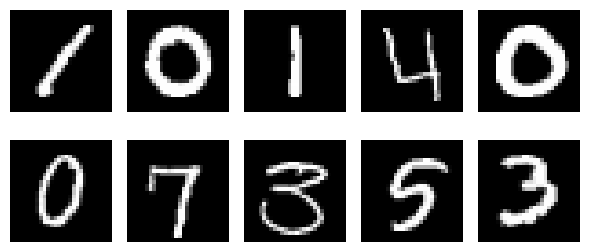

In [5]:
labels = df["label"].head(10).to_list()
print(f"Labels: {labels}")

fig, axes = plt.subplots(2, 5, figsize=(6, 3))
axes = axes.flatten()

for i in range(10):
    pixel_data = df.drop(columns=['label']).iloc[i].values
    image_matrix = pixel_data.reshape(28, 28)

    axes[i].imshow(image_matrix, cmap='gray')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Train Test Split

In [ ]:
train = df.copy()                #               DATA FRAME CAUSE ITS FROM DF COPY
Y = train.pop("label")
# 1. Get the integer index representing 80% of the rows
train = train.astype(np.float64) / 255.0
split_idx = int(len(train) * 0.8)

# 2. Slice the dataframe into two halves
train_split = train.iloc[:split_idx].T
test_split = train.iloc[split_idx:].T

# 3. ADD THIS: Slice the labels into two halves to match!
y_train = Y.iloc[:split_idx]
y_test = Y.iloc[split_idx:]

print(type(train_split))


<class 'pandas.core.frame.DataFrame'>


In [32]:
test_split.iloc[200: 250:, 0]   # All pixels of the first validation image

pixel200    0.000000
pixel201    0.000000
pixel202    0.000000
pixel203    0.000000
pixel204    0.607843
pixel205    0.988235
pixel206    0.960784
pixel207    0.545098
pixel208    0.050980
pixel209    0.000000
pixel210    0.000000
pixel211    0.000000
pixel212    0.000000
pixel213    0.000000
pixel214    0.000000
pixel215    0.164706
pixel216    0.827451
pixel217    0.988235
pixel218    0.815686
pixel219    0.066667
pixel220    0.000000
pixel221    0.000000
pixel222    0.000000
pixel223    0.000000
pixel224    0.000000
pixel225    0.000000
pixel226    0.000000
pixel227    0.000000
pixel228    0.000000
pixel229    0.000000
pixel230    0.000000
pixel231    0.000000
pixel232    0.811765
pixel233    0.988235
pixel234    0.901961
pixel235    0.000000
pixel236    0.000000
pixel237    0.000000
pixel238    0.000000
pixel239    0.000000
pixel240    0.000000
pixel241    0.000000
pixel242    0.000000
pixel243    0.000000
pixel244    0.541176
pixel245    0.988235
pixel246    0.988235
pixel247    0

In [33]:
print(test_split.shape[1])

8400


# Initializing the weights

In [56]:

generate = np.random.default_rng(seed=42)

W1_inputs = train.shape[1]
# Kaiming Initialization Cause we are using ReLu Activation
W1 = generate.standard_normal(size=(10, 784)) * np.sqrt(2.0 / W1_inputs)
b1 = np.zeros((10,1))

W2 = generate.standard_normal(size=(10,10)) * np.sqrt(2.0 / 10)
b2 = np.zeros((10,1))

print("WEIGHT 1==========================================")
print(W1[:,0])
print("WEIGHT 2==========================================")
print(W2[:,0])

WEIGHT 1==========================================
[ 0.01539054  0.00057808  0.03685621 -0.00188137  0.06393129  0.01631817
  0.0366344  -0.04979421  0.02711338  0.1318806 ]
WEIGHT 2==========================================
[ 0.00497449  0.28147532 -0.49256741  0.47523035 -0.25934177 -0.00186881
 -0.23532632  0.2662651  -0.00895189 -0.24040491]


# Helper functions

In [ ]:
def weightedSum(W, b, x):
    return W @ x + b


def ReLu(Z):
    return np.maximum(0, Z)


def softMax(Z):
    Z = np.asarray(Z)
    # Subtracting the max prevents potential overflow (numerical stability)
    # np.max(Z, axis=0, keepdims=True) handles 2D matrices correctly
    exp_Z = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)


# Initializing Training and Eval Variables

In [45]:
epochs = 100
train_batch_size = 100
test_batch_size = 300
train_size = train_split.shape[1] #33600
test_size = test_split.shape[1] # 8400


Y_batch = np.asarray(y_train.iloc[0: train_batch_size])
print(type(Y_batch))

<class 'numpy.ndarray'>


# Training Algorithm

In [58]:
learning_rate = 0.1
patience = 15
rate_decrease_times = 3
rate_decrease_count = 0
epochs_without_improvement = 0
best_validation_loss = float("inf")
best_weights_bias = None


for epoch in range(epochs):
    train_correct = 0
    train_count = 0
    train_loss_sum = 0.0
    for mbatch_x in range(0, train_size, train_batch_size):
        #================================= Forward propagation =================================
        X = train_split.iloc[:, mbatch_x: mbatch_x + train_batch_size].to_numpy()
        m = X.shape[1]
        Z = weightedSum(W1, b1, X) # 10 x m shape
        A = ReLu(Z)                # 10 x m shape
        Z2 = weightedSum(W2, b2, A)# 10 x m shape
        prediction = softMax(Z2)   # 10 x m shape

        # Getting Y labels
        Y = np.asarray(y_train.iloc[mbatch_x: mbatch_x + train_batch_size])
        predicted_classes = np.argmax(prediction, axis=0)
        train_correct += np.sum(predicted_classes == Y)
        train_count += m

        probabilities = prediction[Y, np.arange(m)]
        train_loss_sum += -np.log(
            np.clip(probabilities, 1e-12, 1.0)
        ).sum()

        #================================= Back propagation =================================
        
        
        dZ2 = prediction.copy()#copy it cause python is pass by reference, we are basically pointing dZ2 to prediction and changing dZ2 changes prediction itself
        # Softmax Cross Entropy Loss, the A - Y
        dZ2[Y, np.arange(m)] -=1 
        dW2 = (dZ2 @ A.T) / m
        
        # since columns are the examples, we want to sum every row so axis = 1
        #[] | [] | []   []
        #[] | [] | [] ->[]  1 column
        #[] | [] | []   []      
        db2 = np.sum(dZ2, axis = 1, keepdims = True) / m
        dZ1 = (W2.T @dZ2) * (Z > 0)
        dW1 = (dZ1 @ X.T) / m
        db1 = np.sum(dZ1, axis = 1, keepdims = True) / m # same concept as db2

        # ================================= Optimization (Gradient Descent) =================================
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    
    #================================= TRAINING METRICS CALCULATION =================================

    # Accuracy
    train_accuracy = train_correct / train_count#------------ Accuracy for the batch ------------
    # Loss
    train_loss = train_loss_sum / train_count#------------ Mean loss per batch ------------


    eval_correct = 0
    eval_count = 0
    eval_loss_sum = 0.0
    eval_confusion_matrix = np.zeros((10, 10), dtype=int)
    for mbatch_eval in range(0, test_size, test_batch_size):
        #================================= Forward propagation =================================
        X = test_split.iloc[:, mbatch_eval: mbatch_eval  + test_batch_size].to_numpy()   # taking out 100 inputs at once and feeding it in the net
        Zval = weightedSum(W1, b1, X) # 10 x m
        Aval = ReLu(Zval)  # 10 x m  (m is the train_batch_size)
        Z2val = weightedSum(W2, b2, Aval) # 10 x m
        prediction_val = softMax(Z2val) # 10 x m
        m_val = prediction_val.shape[1]
        Yval = np.asarray(y_test.iloc[mbatch_eval: mbatch_eval  + test_batch_size])

        prediction_classes_eval = np.argmax(prediction_val, axis=0)
        eval_correct += np.sum(prediction_classes_eval == Yval)
        eval_count += m_val

        probabilities = prediction_val[Yval, np.arange(m_val)]
        eval_loss_sum += -np.log(
            np.clip(probabilities, 1e-12, 1.0)
        ).sum()

        for actual, predicted in zip(Yval, prediction_classes_eval):
            eval_confusion_matrix[actual, predicted] += 1

    #================================= EVALUATION METRICS CALCULATION =================================

    # Accuracy
    eval_accuracy = eval_correct / eval_count #------------ Accuracy for the batch ------------
    # Loss
    eval_loss = eval_loss_sum / eval_count #------------ Mean loss per batch ------------

    # Macro F1
    f1_per_class_eval = [] #------------ F1 per class ------------
    for digit in range(10):
        TP = eval_confusion_matrix[digit, digit]
        FP = eval_confusion_matrix[:, digit].sum() - TP
        FN = eval_confusion_matrix[digit, :].sum() - TP
    
        denominator = 2 * TP + FP + FN
        f1 = 2 * TP / denominator if denominator > 0 else 0.0
    
        f1_per_class_eval.append(f1)
    
    macro_f1_eval = np.mean(f1_per_class_eval)

    #================================= EPOCH CONTROLS =================================
    if eval_loss < best_validation_loss: # If the new eval loss is LESSER than the old one, then copy the weights and biases
        best_weights_bias= [W1.copy(), b1.copy(), W2.copy() , b2.copy() ]# copy weights and biases
        best_validation_loss = eval_loss # get the best validation loss 
        epochs_without_improvement = 0
    else: # If no improvements in the loss, then add 1 in the epochs without improvement
        epochs_without_improvement +=1

    if epochs_without_improvement >= patience: # If algorithm loses patience then decrease learning rate, add to rate decrease count and reset epoch improv count
        if rate_decrease_count < rate_decrease_times:
            rate_decrease_count +=1
            learning_rate *= 0.1 #Decrease learning rate by one decimal place
            epochs_without_improvement = 0
        else:
            break #if learning rate is very low, we stop epoch even if it doesnt reach the set epoch

    
        
    #================================= EPOCH METRICS PRINTED =================================
    print(
        f"Epoch {epoch + 1} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation accuracy: {eval_accuracy:.2%} | "
        f"Validation loss: {eval_loss:.4f} | "
        f"Validation macro F1: {macro_f1_eval:.3f}"
    )


print("=========================== Training and Validation is finished ===========================")


print(f"""
Best Validation Loss: {best_validation_loss:.3f}
""")

if best_weights_bias is not None:
    W1, b1, W2, b2 = [p.copy() for p in best_weights_bias]

    
        
        
          

Epoch 1 | Train accuracy: 95.21% | Train loss: 0.1679 | Validation accuracy: 93.64% | Validation loss: 0.2305 | Validation macro F1: 0.935
Epoch 2 | Train accuracy: 95.22% | Train loss: 0.1680 | Validation accuracy: 93.65% | Validation loss: 0.2308 | Validation macro F1: 0.936
Epoch 3 | Train accuracy: 95.24% | Train loss: 0.1674 | Validation accuracy: 93.61% | Validation loss: 0.2311 | Validation macro F1: 0.935
Epoch 4 | Train accuracy: 95.24% | Train loss: 0.1669 | Validation accuracy: 93.63% | Validation loss: 0.2315 | Validation macro F1: 0.935
Epoch 5 | Train accuracy: 95.26% | Train loss: 0.1663 | Validation accuracy: 93.60% | Validation loss: 0.2318 | Validation macro F1: 0.935
Epoch 6 | Train accuracy: 95.28% | Train loss: 0.1658 | Validation accuracy: 93.62% | Validation loss: 0.2321 | Validation macro F1: 0.935
Epoch 7 | Train accuracy: 95.30% | Train loss: 0.1653 | Validation accuracy: 93.60% | Validation loss: 0.2323 | Validation macro F1: 0.935
Epoch 8 | Train accuracy: 9

# Packaging the AI

In [59]:
np.savez(
    "digit_model.npz",
    W1=W1,
    b1=b1,
    W2=W2,
    b2=b2
)
print("gooooods")

gooooods


# Code that uses the AI

##### Packaged together with the savez

In [ ]:
import numpy as np

with np.load("digit_model.npz") as model:
    W1 = model["W1"]
    b1 = model["b1"]
    W2 = model["W2"]
    b2 = model["b2"]


def predict_digit(image):
    # Expects one 28×28 grayscale image with pixel values 0–255.
    X = np.asarray(image, dtype=np.float64).reshape(784, 1) / 255.0

    hidden = np.maximum(0, W1 @ X + b1)
    scores = W2 @ hidden + b2

    exp_scores = np.exp(scores - np.max(scores, axis=0, keepdims=True))
    probabilities = exp_scores / exp_scores.sum(axis=0, keepdims=True)

    predicted_digit = int(np.argmax(probabilities[:, 0]))
    return predicted_digit, probabilities[:, 0]